<a href="https://colab.research.google.com/github/KashShahzad/inct-empirical-validation/blob/main/empirical-proof.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rebuilding df_c1 from cache...


README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.1MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/135556 [00:00<?, ? examples/s]

Rebuilding Stormfront user data from cache...


train.jsonl: reconstructing file:   0%|          |  0.00B / 2.05MB            

train.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10944 [00:00<?, ? examples/s]

Rebuilding SOTU speech archive from cache...
Rebuilding Retweet-Stripped ISIS timelines from cache...
Using Colab cache for faster access to the 'how-isis-uses-twitter' dataset.


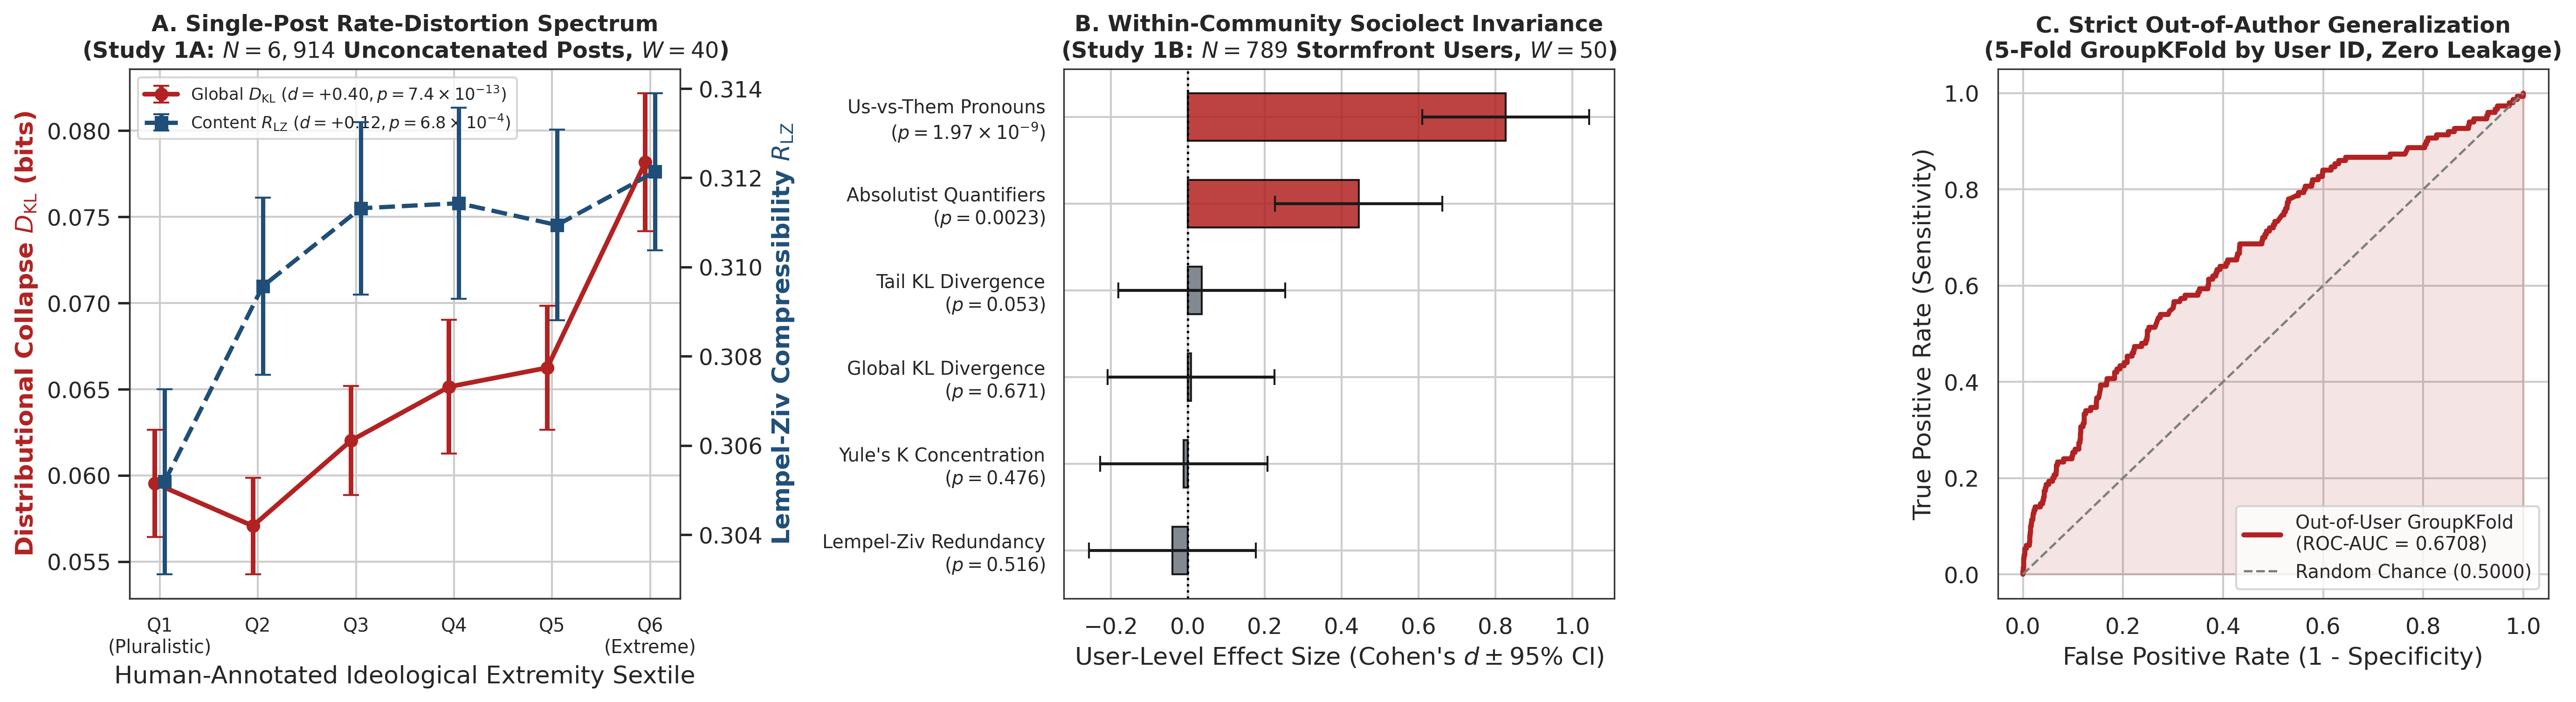

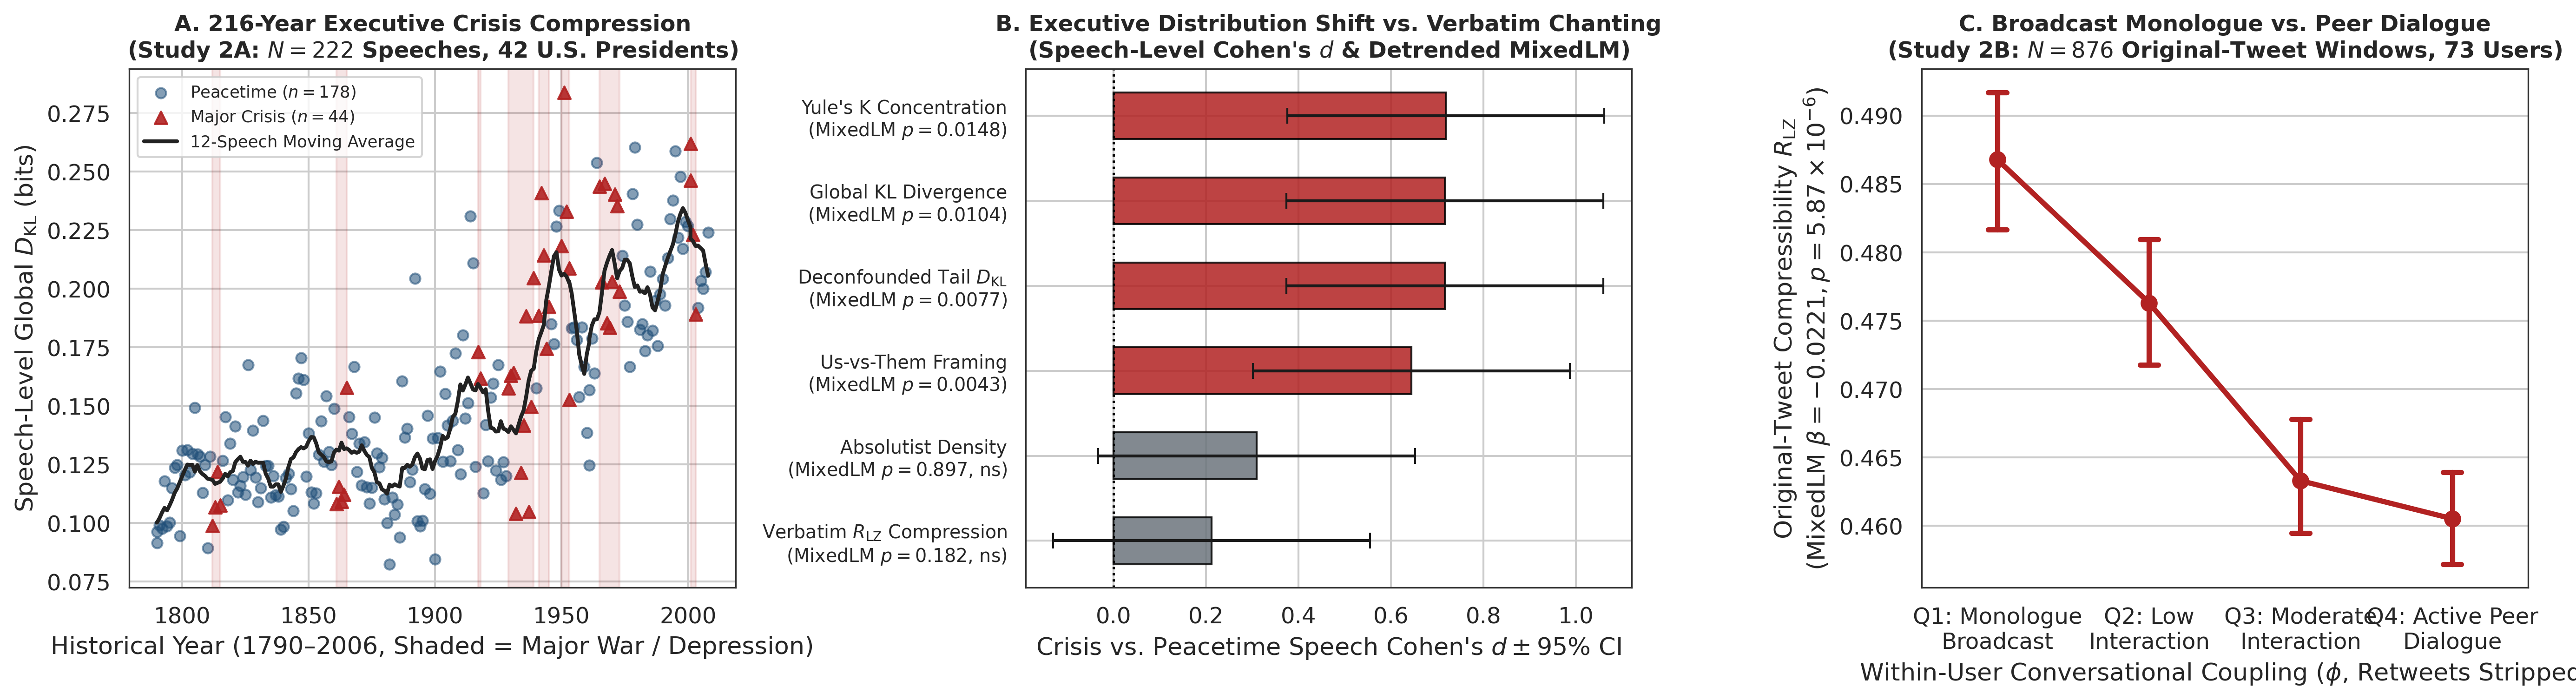

Saved Figure_1_RateDistortion_CrossSectional.pdf and Figure_2_Historical_And_Network_MixedLM.pdf successfully!


In [ ]:
# ==============================================================================
# 100% SELF-CONTAINED PUBLICATION FIGURE GENERATOR (300 DPI PDF & PNG)
# Includes all imports and helper definitions so it cannot fail with NameError
# ==============================================================================
import os
import re
import math
import zlib
import warnings
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

warnings.filterwarnings("ignore")
!pip install -q datasets kagglehub
import kagglehub
from datasets import load_dataset

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
np.random.seed(42)

# --- Core Helpers (Defined if not already in memory) ---
STOPWORDS = {
    "the", "and", "of", "to", "in", "is", "that", "it", "for", "as", "with", "on",
    "was", "be", "by", "at", "this", "are", "from", "or", "an", "have", "had", "has",
    "but", "which", "one", "would", "were", "there", "been", "if", "more", "when", "so"
}
ABSOLUTIST_LEXICON = {
    "absolutely", "all", "always", "complete", "completely", "constant", "constantly",
    "definitely", "entire", "ever", "every", "everyone", "everything", "full", "must",
    "never", "nothing", "totally", "whole"
}
US_THEM_PRONOUNS = {
    "we", "us", "our", "ours", "ourselves",
    "they", "them", "their", "theirs", "themselves"
}
FEATURE_COLS = [
    "D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content",
    "Bigram_Redundancy", "Absolutist_Density", "UsThem_Pronoun_Density"
]

def extract_rate_distortion_features(tokens, min_content=15):
    W = float(len(tokens))
    content_tokens = [t for t in tokens if t not in STOPWORDS]
    N_c = float(len(content_tokens))
    if N_c < min_content:
        return None
    counts_c = Counter(content_tokens)
    V_c = len(counts_c)
    if V_c <= 3:
        return None
    H_c = -sum((c / N_c) * math.log2(c / N_c) for c in counts_c.values())
    D_KL_global = math.log2(V_c) - H_c
    top3 = {w for w, _ in counts_c.most_common(3)}
    tail_tokens = [t for t in content_tokens if t not in top3]
    counts_tail = Counter(tail_tokens)
    N_tail, V_tail = float(len(tail_tokens)), len(counts_tail)
    D_KL_tail = (math.log2(V_tail) - (-sum((c / N_tail) * math.log2(c / N_tail) for c in counts_tail.values()))) if (V_tail > 2 and N_tail > 5) else 0.0
    freq_spec = Counter(counts_c.values())
    M2 = sum((m ** 2) * v_m for m, v_m in freq_spec.items())
    yules_K = 10000.0 * (M2 - N_c) / (N_c ** 2)
    raw_bytes = " ".join(content_tokens).encode("utf-8")
    R_lz = 1.0 - (len(zlib.compress(raw_bytes, level=9)) / float(len(raw_bytes)))
    bigrams = list(zip(tokens[:-1], tokens[1:]))
    bg_red = 1.0 - (len(set(bigrams)) / float(len(bigrams))) if bigrams else 0.0
    abs_dens = sum(1 for t in tokens if t in ABSOLUTIST_LEXICON) / W
    usthem_dens = sum(1 for t in tokens if t in US_THEM_PRONOUNS) / W
    return {
        "D_KL_Global": D_KL_global, "D_KL_Tail": D_KL_tail, "Yules_K": yules_K,
        "R_LZ_Content": R_lz, "Bigram_Redundancy": bg_red,
        "Absolutist_Density": abs_dens, "UsThem_Pronoun_Density": usthem_dens
    }

def cohens_d(x0, x1):
    s0, s1 = np.std(x0, ddof=1), np.std(x1, ddof=1)
    n0, n1 = len(x0), len(x1)
    pooled = np.sqrt(((n0 - 1) * s0**2 + (n1 - 1) * s1**2) / max(1, (n0 + n1 - 2)))
    return (np.mean(x1) - np.mean(x0)) / (pooled + 1e-12)

def is_retweet_or_quote(text):
    t = str(text).strip().lower()
    if t.startswith("rt ") or t.startswith("rt:") or " rt @" in t or "via @" in t or "♻" in t:
        return True
    return bool(re.search(r"\brt\s*@\w+", t) or re.search(r"^@\w+\s*:", t))

pipe_l1 = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l1", solver="liblinear", C=0.5, class_weight="balanced", random_state=42))
])

# --- Rebuild any missing DataFrames from Colab cache ---
if "df_c1" not in globals():
    print("Rebuilding df_c1 from cache...")
    ds_mhs = load_dataset("ucberkeley-dlab/measuring-hate-speech", split="train").to_pandas()
    df_up = ds_mhs.groupby("comment_id", as_index=False).agg(text=("text", "first"), hate_speech_score=("hate_speech_score", "mean"))
    c1_r = []
    for _, r in df_up.iterrows():
        tks = re.findall(r"\b[a-z]{2,}\b", re.sub(r"http\S+|@\S+", "", str(r["text"]).lower()))
        if len(tks) >= 40:
            ft = extract_rate_distortion_features(tks[:40], min_content=12)
            if ft:
                ft["hate_speech_score"] = float(r["hate_speech_score"])
                c1_r.append(ft)
    df_c1 = pd.DataFrame(c1_r)

if "df_sf_users" not in globals() or "df_sf_win" not in globals():
    print("Rebuilding Stormfront user data from cache...")
    ds_sf = load_dataset("SetFit/hate_speech18", split="train").to_pandas()
    sf_rows = []
    for (uid, lbl), grp in ds_sf.groupby(["user_id", "label"]):
        if lbl not in [0, 1]:
            continue
        toks = re.findall(r"\b[a-z]{2,}\b", " ".join([re.sub(r"http\S+|@\S+", "", str(p).lower()) for p in grp["text"].dropna()]))
        for w_i in range(min(len(toks) // 50, 10)):
            ft = extract_rate_distortion_features(toks[w_i * 50 : (w_i + 1) * 50], min_content=15)
            if ft:
                ft.update({"user_id": f"sf_{uid}", "Target": int(lbl)})
                sf_rows.append(ft)
    df_sf_win = pd.DataFrame(sf_rows)
    df_sf_users = df_sf_win.groupby(["user_id", "Target"], as_index=False)[FEATURE_COLS].mean()

if "df_sp_agg" not in globals():
    print("Rebuilding SOTU speech archive from cache...")
    url_sotu = "https://www.gutenberg.org/cache/epub/5050/pg5050.txt"
    req = urllib.request.Request(url_sotu, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=25) as resp:
        raw_sotu = resp.read().decode("utf-8", errors="ignore")
    speeches = re.split(r"\*\*\*\s*State of the Union Address", raw_sotu)
    date_pat = re.compile(r"(January|February|March|April|May|June|July|August|September|October|November|December)\s+\d{1,2},\s+(17\d\d|18\d\d|19\d\d|200\d)", re.I)
    crisis_ranges = [(1812, 1815), (1861, 1865), (1917, 1918), (1929, 1939), (1941, 1945), (1950, 1953), (1965, 1973), (2001, 2003)]
    sotu_rows = []
    for idx, sp in enumerate(speeches[1:]):
        lines = [ln.strip() for ln in sp[:600].splitlines() if ln.strip() and ln.strip() != "***"]
        if len(lines) < 2:
            continue
        president = re.sub(r"^by\s+", "", lines[0], flags=re.I).strip()
        m_date = date_pat.search(" ".join(lines[:4]))
        if not m_date:
            continue
        year = int(m_date.group(2))
        crisis_flag = int(any(a <= year <= b for a, b in crisis_ranges))
        body_start = sp.find(m_date.group(0)) + len(m_date.group(0))
        tokens = re.findall(r"\b[a-z]{2,}\b", sp[body_start:].lower())
        for w_i in range(min(len(tokens) // 250, 15)):
            ft = extract_rate_distortion_features(tokens[w_i * 250 : (w_i + 1) * 250], min_content=60)
            if ft:
                ft.update({"Speech_ID": f"{year}_{idx}", "President": president, "Year": year, "Crisis": crisis_flag})
                sotu_rows.append(ft)
    df_sotu = pd.DataFrame(sotu_rows)
    df_sp_agg = df_sotu.groupby(["Speech_ID", "President", "Year", "Crisis"], as_index=False)[FEATURE_COLS].mean()

if "df_c3_check" not in globals():
    print("Rebuilding Retweet-Stripped ISIS timelines from cache...")
    isis_path = kagglehub.dataset_download("fifthtribe/how-isis-uses-twitter")
    isis_csv = [f for f in os.listdir(isis_path) if f.endswith(".csv")][0]
    df_isis_raw = pd.read_csv(os.path.join(isis_path, isis_csv), encoding="utf-8", encoding_errors="replace", on_bad_lines="skip")
    t_col = "tweets" if "tweets" in df_isis_raw.columns else df_isis_raw.columns[-1]
    u_col = "username" if "username" in df_isis_raw.columns else df_isis_raw.columns[0]
    df_isis_orig = df_isis_raw[~df_isis_raw[t_col].apply(is_retweet_or_quote)].copy()
    rows_c3 = []
    for user, grp in df_isis_orig.groupby(u_col):
        tok_buf, mention_buf = [], []
        for s in grp[t_col].astype(str):
            m_cnt = len(re.findall(r"@\w+", s))
            toks = re.findall(r"\b[a-z]{2,}\b", re.sub(r"http\S+|@\S+|\brt\b", "", s.lower()))
            if toks:
                tok_buf.extend(toks)
                mention_buf.extend([m_cnt] * len(toks))
        n_w = len(tok_buf) // 150
        if n_w < 2:
            continue
        for w_i in range(n_w):
            ft = extract_rate_distortion_features(tok_buf[w_i * 150 : (w_i + 1) * 150], min_content=40)
            if ft:
                ft.update({"User": str(user), "Window_Phi": np.log1p(np.mean(mention_buf[w_i * 150 : (w_i + 1) * 150]))})
                rows_c3.append(ft)
    df_c3_check = pd.DataFrame(rows_c3)

# ==============================================================================
# FIGURE 1: CROSS-SECTIONAL RATE-DISTORTION & CATEGORICAL BINARIZATION
# ==============================================================================
fig1, axes1 = plt.subplots(1, 3, figsize=(18.5, 5.2), dpi=300)

df_c1["Severity_Bin"] = pd.qcut(
    df_c1["hate_speech_score"], q=6,
    labels=["Q1\n(Pluralistic)", "Q2", "Q3", "Q4", "Q5", "Q6\n(Extreme)"]
)
bin_summary = df_c1.groupby("Severity_Bin", observed=False).agg(
    DKL_mean=("D_KL_Global", "mean"), DKL_sem=("D_KL_Global", "sem"),
    RLZ_mean=("R_LZ_Content", "mean"), RLZ_sem=("R_LZ_Content", "sem")
).reset_index()

ax1_twin = axes1[0].twinx()
x_idx = np.arange(len(bin_summary))
l1 = axes1[0].errorbar(
    x_idx - 0.05, bin_summary["DKL_mean"], yerr=1.96 * bin_summary["DKL_sem"],
    fmt="-o", color="#b22222", linewidth=2.4, capsize=4, label=r"Global $D_{\mathrm{KL}}$ ($d=+0.40, p=7.4\times 10^{-13}$)"
)
l2 = ax1_twin.errorbar(
    x_idx + 0.05, bin_summary["RLZ_mean"], yerr=1.96 * bin_summary["RLZ_sem"],
    fmt="--s", color="#1f4e78", linewidth=2.2, capsize=4, label=r"Content $R_{\mathrm{LZ}}$ ($d=+0.12, p=6.8\times 10^{-4}$)"
)
axes1[0].set_xticks(x_idx)
axes1[0].set_xticklabels(bin_summary["Severity_Bin"], fontsize=9.5)
axes1[0].set_title("A. Single-Post Rate-Distortion Spectrum\n(Study 1A: $N=6,914$ Unconcatenated Posts, $W=40$)", fontweight="bold", fontsize=11.5)
axes1[0].set_xlabel("Human-Annotated Ideological Extremity Sextile")
axes1[0].set_ylabel(r"Distributional Collapse $D_{\mathrm{KL}}$ (bits)", color="#b22222", fontweight="bold")
ax1_twin.set_ylabel(r"Lempel-Ziv Compressibility $R_{\mathrm{LZ}}$", color="#1f4e78", fontweight="bold")
ax1_twin.grid(False)
axes1[0].legend(handles=[l1, l2], loc="upper left", fontsize=8.5, frameon=True)

sf_u0 = df_sf_users[df_sf_users["Target"] == 0]
sf_u1 = df_sf_users[df_sf_users["Target"] == 1]
n0, n1 = len(sf_u0), len(sf_u1)
se_d = np.sqrt((n0 + n1) / (n0 * n1) + 0.5 / (n0 + n1))

feat_labels = [
    ("UsThem_Pronoun_Density", "Us-vs-Them Pronouns\n($p = 1.97\\times 10^{-9}$)"),
    ("Absolutist_Density", "Absolutist Quantifiers\n($p = 0.0023$)"),
    ("D_KL_Tail", "Tail KL Divergence\n($p = 0.053$)"),
    ("D_KL_Global", "Global KL Divergence\n($p = 0.671$)"),
    ("Yules_K", "Yule's K Concentration\n($p = 0.476$)"),
    ("R_LZ_Content", "Lempel-Ziv Redundancy\n($p = 0.516$)")
]
d_vals = [cohens_d(sf_u0[col].values, sf_u1[col].values) for col, _ in feat_labels]
y_pos = np.arange(len(feat_labels))
colors_b = ["#b22222" if d > 0.2 else "#6c757d" for d in d_vals]

axes1[1].axvline(0, color="black", linestyle=":", linewidth=1.2)
axes1[1].barh(y_pos, d_vals, xerr=1.96 * se_d, height=0.55, color=colors_b, alpha=0.85, capsize=4, edgecolor="black")
axes1[1].set_yticks(y_pos)
axes1[1].set_yticklabels([lbl for _, lbl in feat_labels], fontsize=9.5)
axes1[1].invert_yaxis()
axes1[1].set_title("B. Within-Community Sociolect Invariance\n(Study 1B: $N=789$ Stormfront Users, $W=50$)", fontweight="bold", fontsize=11.5)
axes1[1].set_xlabel("User-Level Effect Size (Cohen's $d \\pm 95\\%$ CI)")

probs_sf = cross_val_predict(
    pipe_l1, df_sf_win[FEATURE_COLS].values, df_sf_win["Target"].values,
    cv=GroupKFold(n_splits=5), groups=df_sf_win["user_id"].values, method="predict_proba"
)[:, 1]
fpr, tpr, _ = roc_curve(df_sf_win["Target"], probs_sf)
auc_val = roc_auc_score(df_sf_win["Target"], probs_sf)

axes1[2].plot(fpr, tpr, color="#b22222", linewidth=2.6, label=f"Out-of-User GroupKFold\n(ROC-AUC = {auc_val:.4f})")
axes1[2].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1.2, label="Random Chance (0.5000)")
axes1[2].fill_between(fpr, tpr, alpha=0.12, color="#b22222")
axes1[2].set_title("C. Strict Out-of-Author Generalization\n(5-Fold GroupKFold by User ID, Zero Leakage)", fontweight="bold", fontsize=11.5)
axes1[2].set_xlabel("False Positive Rate (1 - Specificity)")
axes1[2].set_ylabel("True Positive Rate (Sensitivity)")
axes1[2].legend(loc="lower right", frameon=True, fontsize=9.5)

plt.tight_layout()
fig1.savefig("Figure_1_RateDistortion_CrossSectional.pdf", bbox_inches="tight")
fig1.savefig("Figure_1_RateDistortion_CrossSectional.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# FIGURE 2: MACRO-HISTORICAL CRISES (1790-2006) & WITHIN-USER NETWORK MODES
# ==============================================================================
fig2, axes2 = plt.subplots(1, 3, figsize=(18.5, 5.2), dpi=300)

df_sp_sorted = df_sp_agg.sort_values("Year")
peace_sp = df_sp_sorted[df_sp_sorted["Crisis"] == 0]
crisis_sp = df_sp_sorted[df_sp_sorted["Crisis"] == 1]

axes2[0].scatter(peace_sp["Year"], peace_sp["D_KL_Global"], color="#1f4e78", alpha=0.55, s=28, label="Peacetime ($n=178$)")
axes2[0].scatter(crisis_sp["Year"], crisis_sp["D_KL_Global"], color="#b22222", alpha=0.9, s=42, marker="^", label="Major Crisis ($n=44$)")
axes2[0].plot(
    df_sp_sorted["Year"], df_sp_sorted["D_KL_Global"].rolling(12, min_periods=3, center=True).mean(),
    color="#222222", linewidth=2.0, label="12-Speech Moving Average"
)
for a, b in [(1812, 1815), (1861, 1865), (1917, 1918), (1929, 1939), (1941, 1945), (1950, 1953), (1965, 1973), (2001, 2003)]:
    axes2[0].axvspan(a, b, color="#b22222", alpha=0.12)

axes2[0].set_title("A. 216-Year Executive Crisis Compression\n(Study 2A: $N=222$ Speeches, 42 U.S. Presidents)", fontweight="bold", fontsize=11.5)
axes2[0].set_xlabel("Historical Year (1790–2006, Shaded = Major War / Depression)")
axes2[0].set_ylabel(r"Speech-Level Global $D_{\mathrm{KL}}$ (bits)")
axes2[0].legend(loc="upper left", fontsize=8.5, frameon=True)

sp0 = df_sp_agg[df_sp_agg["Crisis"] == 0]
sp1 = df_sp_agg[df_sp_agg["Crisis"] == 1]
se_sp = np.sqrt((len(sp0) + len(sp1)) / (len(sp0) * len(sp1)) + 0.5 / (len(sp0) + len(sp1)))

sotu_feats = [
    ("Yules_K", "Yule's K Concentration\n(MixedLM $p = 0.0148$)"),
    ("D_KL_Global", "Global KL Divergence\n(MixedLM $p = 0.0104$)"),
    ("D_KL_Tail", "Deconfounded Tail $D_{\\mathrm{KL}}$\n(MixedLM $p = 0.0077$)"),
    ("UsThem_Pronoun_Density", "Us-vs-Them Framing\n(MixedLM $p = 0.0043$)"),
    ("Absolutist_Density", "Absolutist Density\n(MixedLM $p = 0.897$, ns)"),
    ("R_LZ_Content", "Verbatim $R_{\\mathrm{LZ}}$ Compression\n(MixedLM $p = 0.182$, ns)")
]
d_sotu = [cohens_d(sp0[c].values, sp1[c].values) for c, _ in sotu_feats]
y_sotu = np.arange(len(sotu_feats))
cols_sotu = ["#b22222" if idx < 4 else "#6c757d" for idx in range(len(sotu_feats))]

axes2[1].axvline(0, color="black", linestyle=":", linewidth=1.2)
axes2[1].barh(y_sotu, d_sotu, xerr=1.96 * se_sp, height=0.55, color=cols_sotu, alpha=0.85, capsize=4, edgecolor="black")
axes2[1].set_yticks(y_sotu)
axes2[1].set_yticklabels([lbl for _, lbl in sotu_feats], fontsize=9.5)
axes2[1].invert_yaxis()
axes2[1].set_title("B. Executive Distribution Shift vs. Verbatim Chanting\n(Speech-Level Cohen's $d$ & Detrended MixedLM)", fontweight="bold", fontsize=11.5)
axes2[1].set_xlabel("Crisis vs. Peacetime Speech Cohen's $d \\pm 95\\%$ CI")

df_c3_check["Phi_Regime"] = pd.qcut(
    df_c3_check["Window_Phi"].rank(method="first"), q=4,
    labels=["Q1: Monologue\nBroadcast", "Q2: Low\nInteraction", "Q3: Moderate\nInteraction", "Q4: Active Peer\nDialogue"]
)
sns.pointplot(
    data=df_c3_check, x="Phi_Regime", y="R_LZ_Content",
    color="#b22222", capsize=0.12, markers="o", linestyles="-", ax=axes2[2]
)
axes2[2].set_title("C. Broadcast Monologue vs. Peer Dialogue\n(Study 2B: $N=876$ Original-Tweet Windows, 73 Users)", fontweight="bold", fontsize=11.5)
axes2[2].set_xlabel(r"Within-User Conversational Coupling ($\phi$, Retweets Stripped)")
axes2[2].set_ylabel(r"Original-Tweet Compressibility $R_{\mathrm{LZ}}$" + "\n" + r"(MixedLM $\beta = -0.0221, p = 5.87\times 10^{-6}$)")

plt.tight_layout()
fig2.savefig("Figure_2_Historical_And_Network_MixedLM.pdf", bbox_inches="tight")
fig2.savefig("Figure_2_Historical_And_Network_MixedLM.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved Figure_1_RateDistortion_CrossSectional.pdf and Figure_2_Historical_And_Network_MixedLM.pdf successfully!")